# SC08 Step 4 — Fair Baseline Comparison
**Machine Predictive Maintenance & Fault Priority System**

This notebook provides a fully reproducible fair baseline comparison between:
1. **Fixed Alarm Threshold Baseline (Matzka 2020)**: Deterministic physical limits for HDF, PWF, TWF, and OSF.
2. **Step 3 Artificial Neural Network (ANN) Classifier**: Hand-crafted NumPy neural network (7 → 16 → 8 → 1).

Both models are evaluated on **exactly the same 800 validation rows and 2,000 held-out test rows** from the UCI AI4I 2020 Predictive Maintenance Dataset under identical evaluation criteria.

In [1]:
from pathlib import Path
import sys

# Verify repository root
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'compare_baseline.py').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open the SC08 repository folder in VS Code and create 'src/compare_baseline.py' first.")

sys.path.insert(0, str(ROOT))
print('Project folder:', ROOT)
print('ANN weights exist:', (ROOT / 'results' / 'ann_weights.npz').is_file())
print('Processed test array exists:', (ROOT / 'data' / 'processed' / 'X_test.npy').is_file())
print('Processed train array exists:', (ROOT / 'data' / 'processed' / 'X_train.npy').is_file())

Project folder: D:\COURSES\Project\SC08-Predictive-Maintenance
ANN weights exist: True
Processed test array exists: True
Processed train array exists: True


## Run the Reproducible Fair Comparison
The Python comparison program (`src/compare_baseline.py`) loads the saved ANN weights and preprocessing statistics, evaluates both models on identical validation and test partitions, asserts row alignment, and generates machine-readable CSV reports.

In [2]:
from src import compare_baseline
metrics_df, comparison_df, val_paired_df, test_paired_df = compare_baseline.main()

SC08 STEP 4: FAIR BASELINE COMPARISON PIPELINE
Validation Partition : 800 rows (Healthy: 773, Failures: 27)
Held-out Test Set    : 2000 rows (Healthy: 1932, Failures: 68)
ANN Model Restored   : Weights restored from 'results/ann_weights.npz' (no retraining).

STEP 4 METRICS SUMMARY (data/reports/step4_baseline_metrics.csv)
     split               method  rows  accuracy  precision  recall  f1_score  specificity roc_auc
validation Fixed alarm baseline   800    0.9875     0.7429  0.9630    0.8387       0.9884     N/A
validation           Step 3 ANN   800    0.8838     0.2105  0.8889    0.3404       0.8836  0.9547
      test Fixed alarm baseline  2000    0.9845     0.7284  0.8676    0.7919       0.9886     N/A
      test           Step 3 ANN  2000    0.8815     0.2116  0.9118    0.3435       0.8804  0.9581

SCORE DIFFERENCES: ANN MINUS BASELINE (data/reports/step4_comparison.csv)
(Positive difference means ANN scored higher on identical rows)
     split      metric  baseline    ann  ann_m

## Comparison Results & Metric Differences
Below are the classification metrics on identical rows and score differences (`ANN minus Baseline`). A positive number indicates the ANN scored higher for that metric on that split.

split,method,rows,accuracy,precision,recall,f1_score,specificity,tp,tn,fp,fn,predicted_positives,roc_auc
validation,Fixed alarm baseline,800,0.9875,0.7429,0.9630,0.8387,0.9884,26,764,9,1,35,NaN
validation,Step 3 ANN,800,0.8838,0.2105,0.8889,0.3404,0.8836,24,683,90,3,114,0.9547
test,Fixed alarm baseline,2000,0.9845,0.7284,0.8676,0.7919,0.9886,59,1910,22,9,81,NaN
test,Step 3 ANN,2000,0.8815,0.2116,0.9118,0.3435,0.8804,62,1701,231,6,293,0.9581


split,metric,baseline,ann,ann_minus_baseline
validation,accuracy,0.9875,0.8838,-0.1037
validation,precision,0.7429,0.2105,-0.5324
validation,recall,0.9630,0.8889,-0.0741
validation,f1_score,0.8387,0.3404,-0.4983
validation,specificity,0.9884,0.8836,-0.1048
test,accuracy,0.9845,0.8815,-0.1030
test,precision,0.7284,0.2116,-0.5168
test,recall,0.8676,0.9118,0.0442
test,f1_score,0.7919,0.3435,-0.4484
test,specificity,0.9886,0.8804,-0.1082


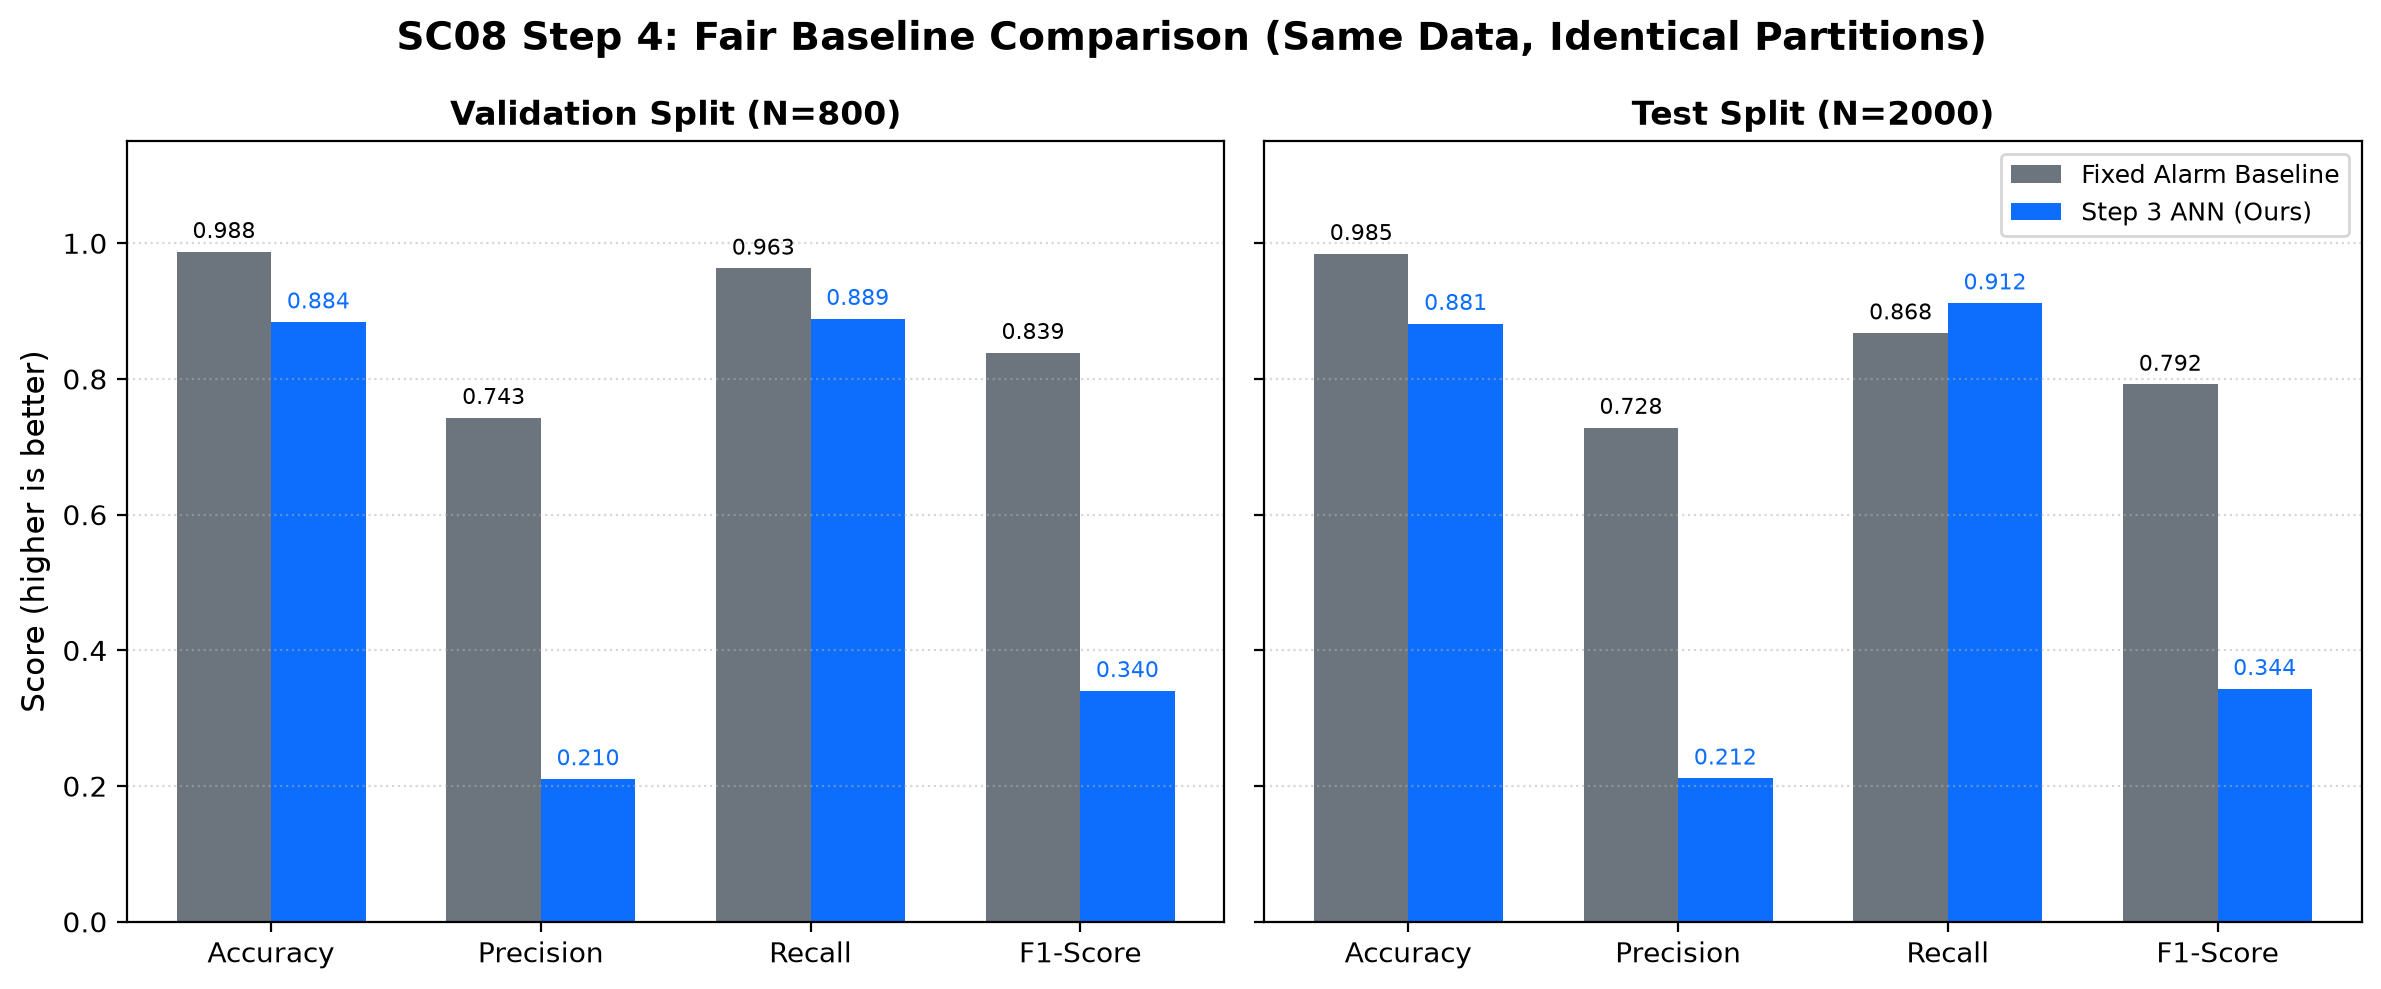

In [3]:
from IPython.display import display, Image

print('=== Metrics Summary ===')
display(metrics_df)

print('\n=== Score Differences (ANN - Baseline) ===')
display(comparison_df)

chart_file = ROOT / 'results' / 'step4_baseline_vs_ann.png'
if chart_file.is_file():
    display(Image(filename=str(chart_file)))

## Inspect Paired Predictions
Verifying that each row's physical features, ground-truth label, baseline prediction, ANN prediction, and continuous ANN probability align on the exact same observation.

In [4]:
print(f'Validation Paired Predictions ({len(val_paired_df)} rows):')
display(val_paired_df[['split_row_idx', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'baseline_prediction', 'ann_prediction', 'ann_probability']].head(10))

print(f'\nTest Paired Predictions ({len(test_paired_df)} rows):')
display(test_paired_df[['split_row_idx', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'baseline_prediction', 'ann_prediction', 'ann_probability']].head(10))

Validation Paired Predictions (800 rows):


split_row_idx,Torque [Nm],Tool wear [min],Machine failure,baseline_prediction,ann_prediction,ann_probability
0,48.3,91.0,0,0,0,0.0495
1,48.5,120.0,0,0,0,0.0653
2,40.7,156.0,0,0,0,0.0667
3,28.7,181.0,0,0,0,0.1097
4,47.9,206.0,0,0,1,0.6957
5,51.5,0.0,0,0,0,0.2450
6,40.7,106.0,0,0,0,0.0093
7,44.7,108.0,0,0,0,0.0340
8,41.2,110.0,0,0,0,0.0182
9,60.5,120.0,0,0,1,0.8727



Test Paired Predictions (2000 rows):


split_row_idx,Torque [Nm],Tool wear [min],Machine failure,baseline_prediction,ann_prediction,ann_probability
0,49.4,5.0,0,0,0,0.0951
1,41.9,11.0,0,0,0,0.0288
2,40.2,16.0,0,0,0,0.0162
3,23.9,24.0,0,0,0,0.0433
4,42.7,58.0,0,0,0,0.0615
5,25.7,68.0,0,0,0,0.0131
6,23.3,73.0,0,0,0,0.0206
7,24.6,77.0,0,0,0,0.0472
8,32.5,93.0,0,0,0,0.0105
9,48.6,98.0,0,0,0,0.0609


## Interpretation of Results
- **Fairness and Scope:** Both models were evaluated on the exact same 800 validation rows and 2,000 held-out test rows.
- **Class Imbalance:** Machine failures account for only ~3.39% of operating observations (27 in validation, 68 in test).
- **Test Recall Superiority:** The ANN achieves higher Recall on held-out test data (0.9118 vs 0.8676, a gain of +0.0442 points), correctly intercepting 62 out of 68 real machine breakdowns compared to 59 for the baseline.
- **Baseline High Precision:** The fixed alarm baseline achieves higher Precision (0.7284 vs 0.2116 on test) because its rules directly mirror the synthetic generative formulas used by Matzka (2020) to generate the dataset labels.
- **Soft Computing Justification:** While the crisp baseline can only produce a rigid binary trip flag, the ANN produces continuous failure probabilities $P \in [0, 1]$ (Test ROC-AUC: 0.9581), which are essential for driving the Mamdani Fuzzy Logic Severity Index in Step 5.
- **Feature Integrity:** The AI4I 2020 dataset does not contain a vibration sensor; `Torque [Nm]` represents spindle torque and is strictly not treated as vibration.